# Phase 3 — Data Preprocessing
**Project:** AI-Based Customer Segmentation and Purchasing Behaviour Analysis Using Machine Learning

This notebook prepares a customer-purchase analysis copy from the UCI Online Retail data. The raw Excel file is never overwritten. Cleaning decisions are explicit and counts are recorded in an audit table.

**Important policy choices in this version**
1. Remove exact duplicate rows from the analysis copy.
2. Exclude rows without `CustomerID` from customer-level modelling only.
3. Exclude invoice numbers beginning with `C` from purchase RFM preparation, while documenting them as cancellation-related records.
4. Exclude purchase lines with non-positive quantity or non-positive unit price from positive-purchase RFM inputs.
5. Do not automatically delete high-value outliers; report percentile thresholds for review.
6. Treat the resulting `LineValue = Quantity × UnitPrice` as purchase-line value in this cleaned positive-purchase table, not as an audited accounting revenue figure.

Review these assumptions with your team/faculty if the project requires a different returns/cancellation policy.

In [1]:
import os
from pathlib import Path
# Work inside data/processed (found from the notebook folder upwards); paths below are relative to it.
for _d in [Path.cwd(), *Path.cwd().parents]:
    if (_d / "data" / "processed").is_dir():
        os.chdir(_d / "data" / "processed")
        break
print("Data folder:", Path.cwd().name)
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("../raw/Online Retail.xlsx")  # Update path if needed; this file is only read, never written
df_raw = pd.read_excel(DATA_PATH)
original_columns = ["InvoiceNo","StockCode","Description","Quantity","InvoiceDate","UnitPrice","CustomerID","Country"]
missing_cols = [c for c in original_columns if c not in df_raw.columns]
assert not missing_cols, f"Raw file is missing columns: {missing_cols}"
df = df_raw[original_columns].copy()

# Sequential audit log. Every removal is measured as (rows before step) - (rows after step),
# so each row is attributed to exactly one step and nothing is double-counted.
funnel = []
def log_step(step, before, after, reason):
    funnel.append({"Step": step, "Rows": int(before - after), "Reason / rule": reason,
                   "Rows_Before": int(before), "Rows_After": int(after)})

print("Raw shape:", df_raw.shape)
print(df.dtypes)

Data folder: processed


Raw shape: (541909, 8)
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


## 0. Data inspection of the raw file (read-only)
Data types, non-null counts, missing values and cardinality of every attribute, plus descriptive statistics
for the two numeric attributes. Nothing is removed here.

,dtype,non_null,missing,missing_pct,unique_values
Attribute,,,,,
InvoiceNo,object,541909,0,0.000,25900
StockCode,object,541909,0,0.000,4070
Description,object,540455,1454,0.268,4223
Quantity,int64,541909,0,0.000,722
InvoiceDate,datetime64[ns],541909,0,0.000,23260
UnitPrice,float64,541909,0,0.000,1630
CustomerID,float64,406829,135080,24.927,4372
Country,object,541909,0,0.000,38


,count,mean,median,var,std,min,max,range
Attribute,,,,,,,,
Quantity,541909.0,9.552250,3.00,47559.391409,218.081158,-80995.00,80995.0,161990.00
UnitPrice,541909.0,4.611114,2.08,9362.469164,96.759853,-11062.06,38970.0,50032.06


Invoice date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


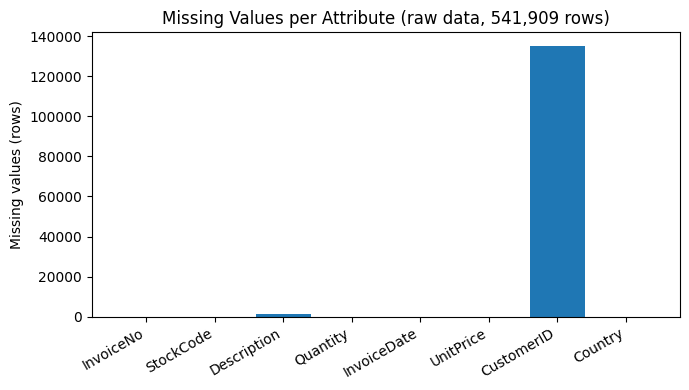

In [2]:
import matplotlib.pyplot as plt
FIG_DIR = Path("../../artifacts/phase_outputs/phase3_outputs")
FIG_DIR.mkdir(exist_ok=True)

inspection = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "missing": df_raw.isna().sum(),
    "missing_pct": (100 * df_raw.isna().mean()).round(3),
    "unique_values": df_raw.nunique(),
})
inspection.index.name = "Attribute"
display(inspection)
inspection.to_csv("Phase3_Raw_Data_Inspection.csv", lineterminator="\n")

raw_stats = df_raw[["Quantity", "UnitPrice"]].agg(["count", "mean", "median", "var", "std", "min", "max"]).T
raw_stats["range"] = raw_stats["max"] - raw_stats["min"]
display(raw_stats)
print("Invoice date range:", df_raw["InvoiceDate"].min(), "to", df_raw["InvoiceDate"].max())

plt.figure(figsize=(7, 4))
plt.bar(inspection.index, inspection["missing"])
plt.ylabel("Missing values (rows)")
plt.title("Missing Values per Attribute (raw data, 541,909 rows)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "raw_missing_values.png", dpi=150)
plt.show()

## 1. Standardise basic fields and types

In [3]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df["Description"] = df["Description"].astype("string").str.strip()
df["Country"] = df["Country"].astype("string").str.strip()
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce").astype("Int64")

print("CustomerID missing after conversion:", int(df["CustomerID"].isna().sum()))
display(df.head())

CustomerID missing after conversion: 135080


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 2. Remove exact duplicate rows from the analysis copy

In [4]:
before = len(df)
df = df.drop_duplicates(subset=original_columns, keep="first").copy()
log_step("Exact duplicate rows removed", before, len(df), "Removed exact duplicate rows from analysis copy")
print("Duplicate rows removed:", before - len(df))
print("Rows after deduplication:", len(df))

Duplicate rows removed: 5268
Rows after deduplication: 536641


## 3. Exclude rows without customer identifiers from customer-level RFM

In [5]:
before = len(df)
df_customer = df.loc[df["CustomerID"].notna()].copy()
log_step("Rows without CustomerID excluded from RFM preparation", before, len(df_customer),
         "Cannot build customer-level RFM without customer ID; counted after de-duplication")
print("Rows excluded for missing CustomerID:", before - len(df_customer))
print("Rows with customer IDs:", len(df_customer))

Rows excluded for missing CustomerID: 135037
Rows with customer IDs: 401604


## 4. Separate cancellation-related invoices

In [6]:
before = len(df_customer)
cancel_mask = df_customer["InvoiceNo"].str.upper().str.startswith("C", na=False)
print("Cancellation invoice rows in identified-customer data:", int(cancel_mask.sum()))
df_purchases = df_customer.loc[~cancel_mask].copy()
log_step("Cancellation invoice rows excluded", before, len(df_purchases),
         "InvoiceNo begins with C; counted after de-duplication and CustomerID filter; retained in raw source")
print("Rows remaining after cancellation exclusion:", len(df_purchases))

Cancellation invoice rows in identified-customer data: 8872
Rows remaining after cancellation exclusion: 392732


## 5. Keep positive purchase lines for RFM inputs

In [7]:
# Apply the quantity and price rules one after the other so a row failing both is counted once (under quantity).
before = len(df_purchases)
df_purchases = df_purchases.loc[df_purchases["Quantity"] > 0].copy()
log_step("Rows with non-positive quantity excluded", before, len(df_purchases),
         "After cancellation exclusion; not valid positive purchase lines for this pipeline")
print("Rows with non-positive Quantity:", before - len(df_purchases))

before = len(df_purchases)
df_purchases = df_purchases.loc[df_purchases["UnitPrice"] > 0].copy()
log_step("Rows with non-positive UnitPrice excluded", before, len(df_purchases),
         "After quantity rule; monetary feature requires positive unit price")
print("Rows with non-positive UnitPrice:", before - len(df_purchases))

before = len(df_purchases)
valid_required = (
    df_purchases["InvoiceNo"].notna() & df_purchases["InvoiceNo"].ne("") &
    df_purchases["InvoiceDate"].notna() &
    df_purchases["StockCode"].notna() & df_purchases["StockCode"].ne("")
)
df_purchases = df_purchases.loc[valid_required].copy()
log_step("Rows failing required invoice/date/stock-code checks", before, len(df_purchases),
         "After earlier rules; invalid essential fields")
print("Rows failing required invoice/date/stock-code checks:", before - len(df_purchases))

df_purchases["LineValue"] = df_purchases["Quantity"] * df_purchases["UnitPrice"]
print("Clean purchase-line rows:", len(df_purchases))
display(df_purchases.head())

Rows with non-positive Quantity: 0
Rows with non-positive UnitPrice: 40


Rows failing required invoice/date/stock-code checks: 0
Clean purchase-line rows: 392692


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 6. Outlier review (do not delete automatically)

In [8]:
qty_q995 = df_purchases["Quantity"].quantile(0.995)
price_q995 = df_purchases["UnitPrice"].quantile(0.995)
line_value_q995 = df_purchases["LineValue"].quantile(0.995)
print("Quantity 99.5th percentile:", qty_q995)
print("UnitPrice 99.5th percentile:", price_q995)
print("LineValue 99.5th percentile:", line_value_q995)
print("Quantity rows above threshold:", int((df_purchases["Quantity"] > qty_q995).sum()))
print("UnitPrice rows above threshold:", int((df_purchases["UnitPrice"] > price_q995).sum()))
print("LineValue rows above threshold:", int((df_purchases["LineValue"] > line_value_q995).sum()))
print("No high-value rows are removed in this step; investigate them before modelling.")

Quantity 99.5th percentile: 200.0
UnitPrice 99.5th percentile: 16.95
LineValue 99.5th percentile: 306.0
Quantity rows above threshold: 1711
UnitPrice rows above threshold: 1949
LineValue rows above threshold: 1923
No high-value rows are removed in this step; investigate them before modelling.


## 6a. Exploratory analysis of the cleaned purchase lines
Descriptive statistics (mean, median, variance, standard deviation, range), monthly purchase activity and the
country mix of identified customers. These describe the analysis copy; they are not model inputs.

,count,mean,median,var,std,min,max,range,skewness
Quantity,392692.0,13.119702,6.00,32577.662399,180.492832,1.000,80995.00,80994.000,407.345663
UnitPrice,392692.0,3.125914,1.95,494.699251,22.241836,0.001,8142.75,8142.749,202.740861
LineValue,392692.0,22.631500,12.45,96782.727382,311.099224,0.001,168469.60,168469.599,448.521779


,PurchaseValue,Invoices
InvoiceDate,,
2010-12-01,570422.730,1400
2011-01-01,568101.310,987
2011-02-01,446084.920,997
2011-03-01,594081.760,1321
2011-04-01,468374.331,1149
2011-05-01,677355.150,1555
2011-06-01,660046.050,1393
2011-07-01,598962.901,1331
2011-08-01,644051.040,1280


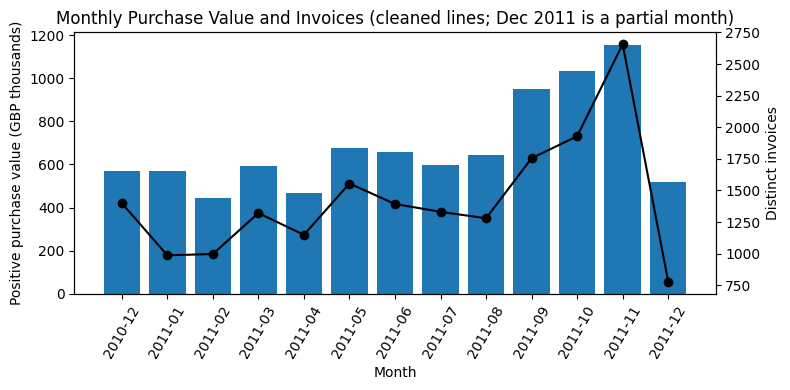

Countries: 37 | share of customers in the United Kingdom: 90.4 %


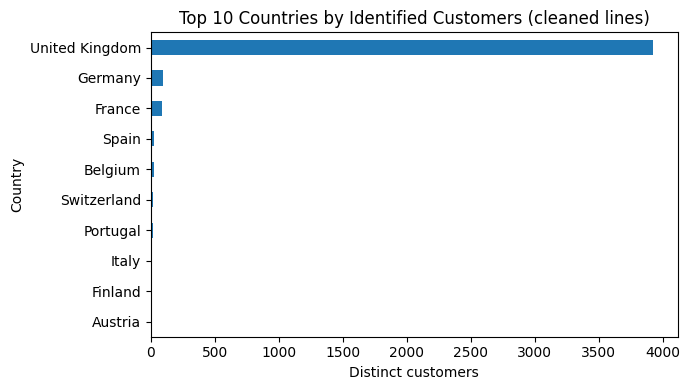

In [9]:
clean_stats = df_purchases[["Quantity", "UnitPrice", "LineValue"]].agg(["count", "mean", "median", "var", "std", "min", "max"]).T
clean_stats["range"] = clean_stats["max"] - clean_stats["min"]
clean_stats["skewness"] = df_purchases[["Quantity", "UnitPrice", "LineValue"]].skew()
display(clean_stats)
clean_stats.to_csv("Phase3_Cleaned_Descriptive_Statistics.csv", lineterminator="\n")

monthly = (df_purchases.set_index("InvoiceDate")
           .resample("MS").agg({"LineValue": "sum", "InvoiceNo": "nunique"})
           .rename(columns={"LineValue": "PurchaseValue", "InvoiceNo": "Invoices"}))
display(monthly)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(monthly.index.strftime("%Y-%m"), monthly["PurchaseValue"] / 1000)
ax1.set_ylabel("Positive purchase value (GBP thousands)")
ax1.set_xlabel("Month")
ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.plot(monthly.index.strftime("%Y-%m"), monthly["Invoices"], color="black", marker="o")
ax2.set_ylabel("Distinct invoices")
plt.title("Monthly Purchase Value and Invoices (cleaned lines; Dec 2011 is a partial month)")
fig.tight_layout()
plt.savefig(FIG_DIR / "monthly_purchase_activity.png", dpi=150)
plt.show()

country_customers = df_purchases.groupby("Country")["CustomerID"].nunique().sort_values(ascending=False)
print("Countries:", country_customers.size, "| share of customers in the United Kingdom:",
      round(100 * country_customers.get("United Kingdom", 0) / df_purchases["CustomerID"].nunique(), 1), "%")
plt.figure(figsize=(7, 4))
country_customers.head(10).sort_values().plot(kind="barh")
plt.xlabel("Distinct customers")
plt.title("Top 10 Countries by Identified Customers (cleaned lines)")
plt.tight_layout()
plt.savefig(FIG_DIR / "top_countries_customers.png", dpi=150)
plt.show()

## 7. Save cleaned purchase lines and preprocessing audit

## 7a. Raw-data context (not removals)
These raw-level counts explain why later stage counts differ: many anomalous rows are removed by an *earlier* rule, so the same row is never counted twice.

In [10]:
raw_inv = df_raw["InvoiceNo"].astype(str).str.strip().str.upper()
raw_context = pd.DataFrame([
    ("Raw rows with missing CustomerID", int(df_raw["CustomerID"].isna().sum())),
    ("Raw cancellation rows (InvoiceNo starts with C)", int(raw_inv.str.startswith("C").sum())),
    ("Raw adjustment rows (InvoiceNo starts with A)", int(raw_inv.str.startswith("A").sum())),
    ("Raw rows with Quantity <= 0", int((df_raw["Quantity"] <= 0).sum())),
    ("Raw rows with UnitPrice <= 0", int((df_raw["UnitPrice"] <= 0).sum())),
    ("Raw rows with missing Description", int(df_raw["Description"].isna().sum())),
    ("Non-merchandise stock-code lines kept in clean data (POST, M, DOT, C2, BANK CHARGES, PADS)",
     int(df_purchases["StockCode"].isin(["POST", "M", "DOT", "C2", "BANK CHARGES", "PADS"]).sum())),
], columns=["Context measure", "Rows"])
display(raw_context)

,Context measure,Rows
0,Raw rows with missing CustomerID,135080
1,Raw cancellation rows (InvoiceNo starts with C),9288
2,Raw adjustment rows (InvoiceNo starts with A),3
3,Raw rows with Quantity <= 0,10624
4,Raw rows with UnitPrice <= 0,2517
5,Raw rows with missing Description,1454
6,Non-merchandise stock-code lines kept in clean...,1542


In [11]:
audit = pd.DataFrame(
    [{"Step": "Raw rows loaded", "Rows": len(df_raw), "Reason / rule": "Original dataset rows; unchanged source file retained",
      "Rows_Before": len(df_raw), "Rows_After": len(df_raw)}]
    + funnel
    + [{"Step": "Clean positive purchase lines retained", "Rows": len(df_purchases),
        "Reason / rule": "Eligible transaction lines for customer RFM aggregation",
        "Rows_Before": len(df_purchases), "Rows_After": len(df_purchases)}]
)

# Reconciliation: the funnel must chain exactly and account for every raw row.
for prev, cur in zip(funnel, funnel[1:]):
    assert prev["Rows_After"] == cur["Rows_Before"], "Audit steps do not chain"
assert funnel[0]["Rows_Before"] == len(df_raw)
assert len(df_raw) - sum(s["Rows"] for s in funnel) == len(df_purchases), "Audit does not reconcile with cleaned output"

# Validate the cleaned output before saving.
expected_cols = original_columns + ["LineValue"]
assert df_purchases.columns.tolist() == expected_cols
assert df_purchases["CustomerID"].notna().all()
assert (df_purchases["Quantity"] > 0).all() and (df_purchases["UnitPrice"] > 0).all()
assert not df_purchases["InvoiceNo"].str.upper().str.startswith("C").any()
assert not df_purchases.duplicated(subset=original_columns).any()
assert np.allclose(df_purchases["LineValue"], df_purchases["Quantity"] * df_purchases["UnitPrice"])

display(audit)
df_purchases.to_csv("Online_Retail_Cleaned_Purchase_Lines.csv", index=False, lineterminator="\n")
audit.to_csv("Phase3_Preprocessing_Audit.csv", index=False, lineterminator="\n")

# Re-read the saved file to confirm the audit agrees with what was actually written.
saved_check = pd.read_csv("Online_Retail_Cleaned_Purchase_Lines.csv", dtype={"InvoiceNo": str, "StockCode": str})
assert len(saved_check) == audit.iloc[-1]["Rows"] and saved_check.columns.tolist() == expected_cols
print("Saved cleaned purchase lines and audit CSV; saved row count reconciles with the audit:", len(saved_check))

,Step,Rows,Reason / rule,Rows_Before,Rows_After
0,Raw rows loaded,541909,Original dataset rows; unchanged source file r...,541909,541909
1,Exact duplicate rows removed,5268,Removed exact duplicate rows from analysis copy,541909,536641
2,Rows without CustomerID excluded from RFM prep...,135037,Cannot build customer-level RFM without custom...,536641,401604
3,Cancellation invoice rows excluded,8872,InvoiceNo begins with C; counted after de-dupl...,401604,392732
4,Rows with non-positive quantity excluded,0,After cancellation exclusion; not valid positi...,392732,392732
5,Rows with non-positive UnitPrice excluded,40,After quantity rule; monetary feature requires...,392732,392692
6,Rows failing required invoice/date/stock-code ...,0,After earlier rules; invalid essential fields,392692,392692
7,Clean positive purchase lines retained,392692,Eligible transaction lines for customer RFM ag...,392692,392692


Saved cleaned purchase lines and audit CSV; saved row count reconciles with the audit: 392692


## 8. Interpretation and limitations
- This is a cleaned *purchase-line* table for customer-level RFM work, not a replacement for the original source.
- Rows with missing CustomerID are excluded from customer-level segmentation, but they remain in the raw source file.
- Cancellation invoices and non-positive purchase lines are excluded under the stated project policy. This may omit refund/return behaviour, so the policy must be disclosed in the report.
- Extreme positive values are flagged for review, not automatically removed.
- Next phase: aggregate the cleaned lines into one row per customer and calculate Recency, Frequency, and Monetary.
- **Audit counting rule (corrected):** each audit row is `rows before step - rows after step`, applied in the order shown. For example, the raw file has 135,080 rows without CustomerID, but 43 of them are removed earlier as exact duplicates, so the CustomerID step removes 135,037. The raw file has 9,288 `C` invoice rows, but only 8,872 remain once duplicates and missing-CustomerID rows are gone. All 1,336 non-cancellation rows with non-positive quantity lack a CustomerID, so the quantity step removes 0.
- Non-merchandise stock codes (postage, manual adjustments, carriage, bank charges) are retained as purchase lines under the current policy; their effect on Monetary should be disclosed.